<a href="https://colab.research.google.com/github/joiepark/assignment_esaa/blob/main/261116_%EC%8B%9C%EA%B3%84%EC%97%B4%EB%B6%84%EC%84%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## LSTM

*   RNN의 결정적 단점은 가중치가 업데이트되는 과정에서 기울기가 1보다 작은 값이 계속 곱해지기 때문에 기울기가 사라지는 기울기 소멸 문제가 발생한다는 것임. 이를 해결하기 위해 LSTM이나 GRU 같은 확장된 RNN 방식들을 사용하고 있음.
### LSTM 구조 - LSTM 순전파

*   LSTM은 기울기 소멸 문제를 해결하기 위해 망각 게이트, 입력 게이트, 출력 게이트라는 새로운 요소를 은닉층의 각 뉴런에 추가함.
1. 망각 게이트(forget gate): 과거 정보를 어느 정도 기억할지 결정함. 과거 정보와 현재 데이터를 입력받아 시그모이드를 취한 후 그 값을 과거 정보에 곱해줌. 따라서 시그모이드의 출력이 0이면 과거 정보는 버리고, 1이면 과거 정보는 온전히 보존함.
2. 입력 게이트(input gate): 현재 정보를 기억하기 위해 만들어짐. 과거 정보와 현재 데이터를 입력받아 시그모이드와 하이퍼볼릭 탄젠트 함수를 기반으로 현재 정보에 대한 보존량을 결정함. 즉, 현재 메모리에 새로운 정보를 반영할지 결정하는 역할을 함.
3. 셀: 각 단계에 대한 은닉 노드를 메모리 셀이라고 함. 총합을 사용해 셀 값을 반영하며, 이것으로 기울기 소멸 문제가 해결됨. 망각 게이트와 입력 게이트의 이전 단계 셀 정보를 계산해 현재 단계의 셀 상태를 업데이트할 수 있음.
4. 출력 게이트(output gate): 과거 정보와 현재 데이터를 사용해 뉴런의 출력을 결정함. 이전 은닉 상태(hidden state) 와 t번째 입력을 고려해 다음 은닉 상태를 계산함. 그리고 LSTM에서는 이 은닉 상태가 그 시점에서의 출력이 됨. 결론적으로 출력 게이트는 갱신된 메모리의 출력 값을 제어하는 역할을 함.
### LSTM 구조 - LSTM 역전파
*   LSTM은 셀을 통해서 역전파를 수행하기 때문에 중단 없는 기울기(uninterrupted gradient flow)라고도 함. 즉 최종 오차는 모든 노드에 전파되는데, 이 때 셀을 통해서 중단 없이 전파됨. 이 때 주의해야 할 것은 셀 단위로 오차가 전파된다고 해서 입력 방향으로 오차가 전파되지 않는 것은 아니라는 것임. 셀 내부적으로는 오차가 입력으로 전파됨.

## LSTM 셀 구현

*   MNIST: 인공지능 연구의 권위자 Yann LeCun 교수가 만든 데이터셋으로, 훈련 데이터셋 6만 개와 검증 데이터셋 1만 개로 구성되어 있음. 손으로 쓴 숫자 이미지(0에서 9까지 값을 갖는 고정 크기 이미지(28 X 28) 픽셀)들로 구성되어 있음.


In [1]:
## 라이브러리 호출

import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.autograd import Variable
from torch.nn import Parameter   ## 파라미터 목록을 가지고 있는 라이브러리(패키지)
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math   ## 수학과 관련되어 다양한 함수들과 상수들이 정의되어 있는 라이브러리

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False   ## GPU 사용에 필요

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor   ## GPU 사용에 필요함

torch.manual_seed(125)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(125)

In [2]:
## 데이터 전처리

import torchvision.transforms as transforms

mnist_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (1.0,))])   ## 평균을 0.5, 표준편차를 1.0으로 데이터 정규화

* MNIST 데이터셋을 내려받기 위해 필요한 파라미터
1. 첫 번째 파라미터: MNIST를 내려받을 위치 지정
2. transform: 앞에서 정의했던 데이터 전처리 적용
3. train: True로 설정할 경우 훈련용 데이터셋을, False로 설정할 경우 테스트용 데이터셋을 가져옴.
4. download: True로 설정할 경우 내려받으려는 위치에 MNIST 파일이 없으면 내려받지만 있으면 내려받지 않음.

In [3]:
## 데이터셋 내려받기

from torchvision.datasets import MNIST

download_root = '../chap07/MNIST_DATASET'  ## MNIST를 내려받을 경로

train_dataset = MNIST(download_root, transform=mnist_transform, train=True, download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.94MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 138kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.65MB/s]


In [4]:
## 데이터셋을 메모리로 가져오기

batch_size = 64
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(dataset=valid_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

In [5]:
## 변수 값 지정

batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

* LSTM에서 중요한 것은 게이트임.

```
gates = F.linear(input, w_ih, b_ih) + F.linear(hx, w_hh, b_hh)

# input: 입력층으로 입력되는 훈련 데이터셋의 특성(feature) 수, 즉 칼럼 개수
# w_ih: 입력층과 은닉층 사이의 가중치
# b_ih: 입력층과 은닉층 사이의 bias
# hx: 은닉층의 뉴런/유닛 개수(은닉층의 특성(feature) 수)
# w_hh: 은닉층과 은닉층 사이의 가중치
# b_hh: 은닉층과 은닉층 사이의 bias
```
이렇게 계산된 게이트는 gates.chunk(4,1)에 의해 네 개로 쪼개져서 각각 망각, 입력, 셀, 출력 게이트를 의미하는 변수에 저장됨. 즉, gates가 네 개로 쪼개지는 상황이기 때문에 은닉층의 뉴런과 유닛에 4가 곱해짐. 일반적으로 bias에도 4를 곱해줌.
* torch.chunk는 텐서를 쪼갤 때 사용하는 함수이며, 파라미터는 다음과 같음.
1. 첫 번째 파라미터: 텐서를 몇 개로 쪼갤지 설정함.
2. 두 번째 파라미터: 어떤 차원을 기준으로 쪼갤지 결정함.
* uniform()은 난수를 위해 사용함.
* torch.squeeze()는 텐서를 차원을 줄이고자 할 때 사용함.
* torch.mul()은 텐서에 곱셈을 할 때 사용함.

In [16]:
## LSTM 셀 네트워크 구축

class LSTMCell(nn.Module):
  def __init__(self, input_size, hidden_size, bias=True):
    super(LSTMCell, self).__init__()
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.bias = bias
    self.x2h = nn.Linear(input_size, 4 * hidden_size, bias=bias)
    self.h2h = nn.Linear(hidden_size, 4 * hidden_size, bias=bias)
    self.reset_parameters()

  def reset_parameters(self):
    std = 1.0 / math.sqrt(self.hidden_size)
    for w in self.parameters():
      w.data.uniform_(-std, std)

  def forward(self, x, hidden):
    hx, cx = hidden
    x = x.view(-1, x.size(1))

    gates = self.x2h(x) + self.h2h(hx)
    gates = gates.squeeze()
    ingate, forgetgate, cellgate, outgate = gates.chunk(4,1)

    ingate = F.sigmoid(ingate)  ## 입력 게이트에 시그모이드 활성화 함수 적용
    forgetgate = F.sigmoid(forgetgate)  ## 망각 게이트에 시그모이드 활성화 함수 적용
    cellgate = F.tanh(cellgate)   ## 셀 게이트에 탄젠트 활성화 함수 적용
    outgate = F.sigmoid(outgate)   ## 출력 게이트에 시그모이드 활성화 함수 적용

    cy = torch.mul(cx, forgetgate) + torch.mul(ingate, cellgate)
    hy = torch.mul(outgate, F.tanh(cy))
    return(hy, cy)

* LSTM 셀은 앞에서 정의한 함수를 불러오는 부분으로 파라미터는 다음과 같음.
1. input_dim: 입력에 대한 특성(feature) 수, 즉 칼럼 개수
2. hidden_dim: 은닉층의 뉴런 개수
3. layer_dim: 은닉층의 계층 개수

In [17]:
## LSTM 셀의 전반적인 네트워크

class LSTMModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
    super(LSTMModel, self).__init__()
    self.hidden_dim = hidden_dim   ## 은닉층의 뉴런/유닛 개수

    self.layer_dim = layer_dim
    self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
    self.fc = nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    if torch.cuda.is_available():
      ## GPU 사용 유무 확인
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())  ## (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 형태를 갖는 은닉 상태를 0으로 초기화
    else:
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    if torch.cuda.is_available():
      ## GPU 사용 유무 확인
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())  ## (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 향태를 갖는 셀 상태를 0으로 초기화
    else:
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    outs = []
    cn = c0[0,:,:]  ## (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 크기를 갖는 셀 상태에 대한 텐서
    hn = h0[0,:,:]   ## (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 크기를 갖는 은닉 상태에 대한 텐서

    for seq in range(x.size(1)):
      ## LSTM 셀 계층을 반복해 쌓아 올림
      hn, cn = self.lstm(x[:, seq, :], (hn, cn))
      outs.append(hn)

    out = outs[-1].squeeze()
    out = self.fc(out)
    return out

In [18]:
## 옵티마이저와 손실 함수 지정

input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available():
  ## GPU 사용 유무 확인
  model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [19]:
## 모델 학습 및 성능 확인

seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    ## 훈련 데이터셋을 이용한 모델 학습
    if torch.cuda.is_available():
      ## GPU 사용 확인
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = Variable(labels.cuda())
    else:
      ## GPU를 사용하지 않기 때문에 else 구문이 실행
      images = Variable(images.view(-1, seq_dim, input_dim))
      labels = Variable(labels)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)

    if torch.cuda.is_available():
      loss.cuda()

    loss.backward()
    optimizer.step()   ## 파라미터 업데이트
    loss_list.append(loss.item())
    iter += 1

    if iter % 500 == 0:
      ## 정확도 계산
      correct = 0
      total = 0
      for images, labels in valid_loader:
        ## 검증 데이터셋을 이용한 모델 성능 검증
        if torch.cuda.is_available():
          images = Variable(images.view(-1, seq_dim, input_dim)).cuda()
        else:
          images = Variable(images.view(-1, seq_dim, input_dim))
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)   ## 모델을 통과한 결과의 최댓값으로부터 예측 결과 가져오기

        total += labels.size(0)   ## 총 레이블 수
        if torch.cuda.is_available():
          correct += (predicted.cpu() == labels.cpu()).sum()
        else:
          correct += (predicted == labels).sum()

      accuracy = 100 * correct / total
      print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))

Iteration: 500. Loss: 2.2422852516174316. Accuracy: 19.850000381469727
Iteration: 1000. Loss: 0.7828241586685181. Accuracy: 73.76000213623047
Iteration: 1500. Loss: 0.43104758858680725. Accuracy: 87.54000091552734
Iteration: 2000. Loss: 0.22590933740139008. Accuracy: 93.2300033569336
Iteration: 2500. Loss: 0.3886856138706207. Accuracy: 94.87999725341797
Iteration: 3000. Loss: 0.17353728413581848. Accuracy: 95.61000061035156
Iteration: 3500. Loss: 0.10650205612182617. Accuracy: 96.81999969482422
Iteration: 4000. Loss: 0.07142030447721481. Accuracy: 96.69000244140625
Iteration: 4500. Loss: 0.048013150691986084. Accuracy: 96.69000244140625
Iteration: 5000. Loss: 0.09317725896835327. Accuracy: 96.88999938964844
Iteration: 5500. Loss: 0.05581437423825264. Accuracy: 96.79000091552734
Iteration: 6000. Loss: 0.11943211406469345. Accuracy: 97.43000030517578
Iteration: 6500. Loss: 0.0379384346306324. Accuracy: 97.87999725341797
Iteration: 7000. Loss: 0.041444092988967896. Accuracy: 97.8199996948

In [20]:
## 테스트 데이터셋을 이용한 모델 예측 성능 확인

def evaluate(model, val_iter):
  corrects, total, total_loss = 0, 0, 0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available():
      ## GPU 사용 유무 확인
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
    else:
      images = Variable(images.view(-1, seq_dim, input_dim)).to(device)

    logit = model(images).to(device)
    loss = F.cross_entropy(logit, labels, reduction="sum")
    _, predicted = torch.max(logit.data, 1)   ## logit.data 텐서에서 최댓값의 인덱스를 반환
    total += labels.size(0)
    total_loss += loss.item()
    corrects += (predicted == labels).sum()

  avg_loss = total_loss / len(val_iter.dataset)
  avg_accuracy = corrects / total
  return avg_loss, avg_accuracy

### LSTM 계층 구현

In [25]:
## 라이브러리 호출

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [27]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 15.96 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [36]:
data = pd.read_csv('080289/chap07/data/SBUX.csv')
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object




*   단어들로 구성된 데이터셋은 임베딩 과정을 거쳐야 함.


In [37]:
## 날짜 칼럼을 인덱스로 사용

data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)

In [38]:
## 정수 데이터 형식을 실수로 변경

data['Volume'] = data['Volume'].astype(float)

In [39]:
## 훈련과 레이블 분리

X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12



*  데이터셋에서 데이터 간의 분포가 다르게 나타날 때 분포를 고르게 맞추기 위해 MinMaxScaler()와 StandardScaler()를 사용해 분산을 조정함.




In [40]:
## 데이터 분포 조정

ms = MinMaxScaler()  ## 데이터의 모든 값이 0~1 사이에 존재하도록 분산 조정
ss = StandardScaler()  ## 데이터가 평균 0, 분산 1이 되도록 분산 조정

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]  ## 훈련 데이터셋
X_test = X_ss[200:, :]  ## 테스트 데이터셋

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


* torch.reshape은 텐서의 형태를 바꿀 때 사용하며, 여기서는 훈련 데이터셋(X_train_tensors)의 형태 (200,5)를 (200, 1, 5)로 변경하겠다는 의미임. 이와 같이 데이터셋의 형태를 변경하는 이유는 LSTM 네트워크의 입력 형태와 맞추기 위함임.

In [42]:
## 데이터셋의 형태 및 크기 조정

X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0], 1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0], 1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("TestingShape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
TestingShape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [47]:
## LSTM 네트워크

class LSTM(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(LSTM, self).__init__()
    self.num_classes = num_classes  ## 클래스 개수
    self.num_layers = num_layers  ## LSTM 계층의 개수
    self.input_size = input_size  ## 입력 크기로 훈련 데이터셋의 칼럼 개수 의미
    self.hidden_size = hidden_size  ## 은닉층의 뉴런 개수
    self.seq_length = seq_length  ## 시퀀스 길이

    self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
    self.fc_1 = nn.Linear(hidden_size, 128)  ## 완전연결층 (nn.linear -> nn.Linear)
    self.fc = nn.Linear(128, num_classes) ## 출력층 (nn.linear -> nn.Linear)
    self.relu = nn.ReLU()

  def forward(self, x):
    h_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))  ## 은닉 상태를 0으로 초기화
    c_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))  ## 셀 상태를 0으로 초기화
    output, (hn, cn) = self.lstm(x, (h_0, c_0))  ## LSTM 계층에 은닉 상태와 셀 상태 적용
    hn = hn.view(-1, self.hidden_size)  ## 완전연결층 적용을 위해 데이터의 형태 조정
    out = self.relu(hn)
    out = self.fc_1(out)
    out = self.relu(out)
    out = self.fc(out)
    return out

In [48]:
## 변수 값 설정

num_epochs = 1000
learning_rate = 0.0001

input_size = 5    ## 입력 데이터셋의 칼럼 개수
hidden_size = 2    ## 은닉층의 뉴런/유닛 개수
num_layers = 1   # LSTM 계층의 개수

num_classes = 1  ## 클래스 개수
model = LSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1])

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [50]:
## 모델 학습

for epoch in range(num_epochs):
  outputs = model.forward(X_train_tensors_f)  ## 전방향 학습
  optimizer.zero_grad()
  loss = criterion(outputs, y_train_tensors)  ## 손실함수를 이용한 오차 계산(모델 학습 결과(outputs)와 레이블(y_train_tensors)의 차이 계산)
  loss.backward()  ## 기울기 계산

  optimizer.step()  ## 오차 업데이트
  if epoch % 100 == 0:
    print("Epoch: %d, loss: %1.5f" % (epoch,loss.item()))

Epoch: 0, loss: 0.10994
Epoch: 100, loss: 0.04680
Epoch: 200, loss: 0.04057
Epoch: 300, loss: 0.03743
Epoch: 400, loss: 0.03460
Epoch: 500, loss: 0.03169
Epoch: 600, loss: 0.02855
Epoch: 700, loss: 0.02561
Epoch: 800, loss: 0.02309
Epoch: 900, loss: 0.02111


In [56]:
## 모델 예측 결과를 출력하기 위한 데이터 크기 재구성

df_x_ss = ss.transform(data.iloc[:, :-1])
df_y_ms = ms.transform(data.iloc[:, -1:])

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

* axvline()은 그래프의 축을 따라 수직선으 ㄹ표현할 때 사용하며 파라미터는 다음과 같음.
1. 첫 번째 파라미터: 어떤 지점에 수직선 표현할지 지정함.
2. c: 어떤 색상으로 수직선 표현할지 지정함.
3. linestyle: 어떤 스타일로 수직선을 표현할지 지정함. 참고로 수평선은 axhline()을 사용함.

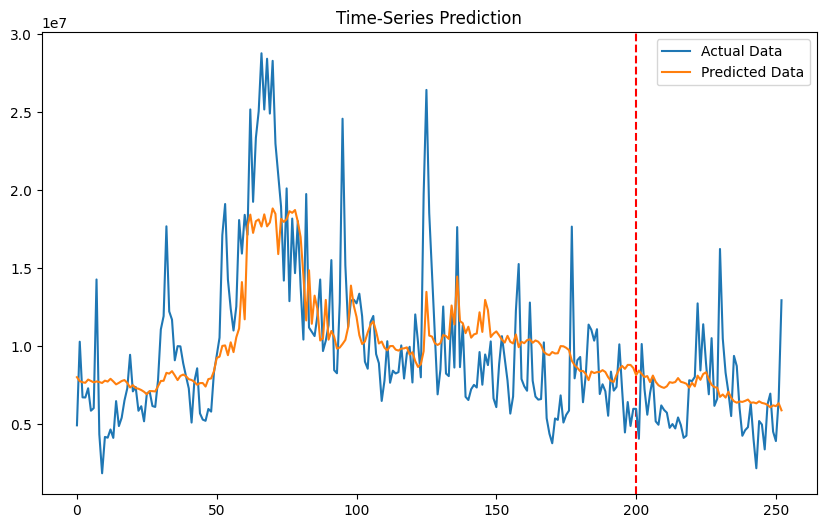

In [59]:
## 모델 예측 결과 출력

train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)  ## 모델 학습을 위해 전처리(정규화)했던 것을 해제해 그래프의 본래 값을 출력
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10,6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()